# Bài tập 2 - Hồng Gấm

Môn 121036. Người phụ trách: **Hồng Gấm**.

Hoàn thành nội bộ: **18/11/2026**. Hạn nộp: **20/11/2026**.

Vòng 1 (Phần A - Harris dùng chung): đã cài đặt `gaussian_blur`, `structure_tensor`, `harris_response`, `nms_2d`, `harris_classic`, `repeatability` và chạy kiểm chứng A1, A2, A4. Phần thí nghiệm ba cặp làm ở vòng sau.

Quy ước tọa độ: điểm là `(row, col)`; ma trận 3x3 truyền vào `repeatability` theo quy ước OpenCV, tác động lên `(x, y, 1) = (col, row, 1)`.

## 0. Chuẩn bị môi trường

Cell bên dưới do Codex tạo để import thư viện và xác định đường dẫn, ngoài phần cài đặt thuật toán. Các cell cài đặt được để trống.

**Khai báo AI cho cell chuẩn bị**

- Công cụ: Codex (OpenAI).
- Mục đích: tạo bộ khung thư mục, notebook và đường dẫn dùng chung.
- Prompt nguyên văn:

> giờ bạn tạo cái sườn giúp tôi [https://github.com/NguyenTanHiep07/xla-121036](https://github.com/NguyenTanHiep07/xla-121036) làm tiếp trong này cho dễ nha tạo mấy thư mục mấy cũ ko liên quan á bỏ qua

In [1]:
from pathlib import Path
import math
import time

import numpy as np
import matplotlib.pyplot as plt

# Chuẩn bị đường dẫn, không cài đặt thuật toán.
thu_muc_chay = Path.cwd().resolve()
thu_muc_tim = (
    thu_muc_chay,
    thu_muc_chay / "bai_tap_2",
    thu_muc_chay.parent,
)
BT2_DIR = next(
    (p for p in thu_muc_tim if (p / "bt2_nhom.ipynb").is_file()),
    None,
)
if BT2_DIR is None:
    raise FileNotFoundError(
        "Chọn thư mục chạy là gốc repo, bai_tap_2 hoặc bai_tap_2/lam_viec."
    )
IMAGES_DIR = BT2_DIR.parent / "images"
print("Bài tập 2:", BT2_DIR)
print("Ảnh dùng chung:", IMAGES_DIR)


Bài tập 2: /Users/tanhiep/Desktop/xla-121036/bai_tap_2
Ảnh dùng chung: /Users/tanhiep/Desktop/xla-121036/images


## Cài đặt - KHÔNG dùng AI

Tự viết các hàm ở những cell trống bên dưới. Chữ ký và đầu ra trong markdown là bản nhắc đặc tả của đề; không có mã thuật toán được tạo sẵn. Không dùng AI để viết, sửa lỗi hay viết lại phần này theo quy định của đề.

### `gaussian_blur(img, sigma)`

Làm mờ Gauss; được phép dùng scipy.ndimage.gaussian_filter.

In [2]:

def gaussian_blur(img, sigma):
    img = np.asarray(img, dtype=np.float64)

    if sigma <= 0:
        return img.copy()

    radius = int(np.ceil(3 * sigma))
    x = np.arange(-radius, radius + 1, dtype=np.float64)

    kernel_1d = np.exp(-(x ** 2) / (2 * sigma ** 2))
    kernel_1d /= kernel_1d.sum()

    kernel = np.outer(kernel_1d, kernel_1d)

    padded = np.pad(img, radius, mode="reflect")
    result = np.zeros_like(img)

    for i in range(kernel.shape[0]):
        for j in range(kernel.shape[1]):
            result += kernel[i, j] * padded[
                i:i + img.shape[0],
                j:j + img.shape[1]
            ]

    return result


### `structure_tensor(img, sigma_i, sigma_d)`

Trả (Mxx, Mxy, Myy), mỗi mảng cùng kích thước ảnh; có hệ số sigma_d**2 theo đề.

In [3]:

def structure_tensor(img, sigma_i, sigma_d):
    img = np.asarray(img, dtype=np.float64)

    if img.ndim != 2:
        raise ValueError("img phải là ảnh xám 2 chiều (H, W)")

    if sigma_i <= 0 or sigma_d <= 0:
        raise ValueError("sigma_i và sigma_d phải dương")

    blurred = gaussian_blur(img, sigma_d)

    Iy, Ix = np.gradient(blurred)

    factor = sigma_d ** 2

    Mxx = factor * gaussian_blur(Ix ** 2, sigma_i)
    Mxy = factor * gaussian_blur(Ix * Iy, sigma_i)
    Myy = factor * gaussian_blur(Iy ** 2, sigma_i)

    return Mxx, Mxy, Myy


### `harris_response(img, sigma_i, sigma_d, k=0.04)`

Trả đáp ứng R dạng mảng float cùng kích thước ảnh.

In [4]:

def harris_response(img, sigma_i, sigma_d, k=0.04):
    Mxx, Mxy, Myy = structure_tensor(
        img, sigma_i, sigma_d
    )

    det = Mxx * Myy - Mxy ** 2
    trace = Mxx + Myy

    R = det - k * trace ** 2

    return R


### `nms_2d(response, window=3)`

Trả mảng bool đánh dấu cực đại địa phương.

In [5]:

def nms_2d(response, window=3):
    """Đánh dấu cực đại địa phương trong cửa sổ window x window.

    Khi nhiều pixel trong cùng cửa sổ có đáp ứng bằng nhau (đồng hạng),
    chỉ giữ pixel đứng trước theo thứ tự quét (hàng trước, cột sau):
    pixel phải lớn hơn hẳn các láng giềng đứng trước nó và
    lớn hơn hoặc bằng các láng giềng đứng sau nó.
    """
    response = np.asarray(response, dtype=np.float64)

    if response.ndim != 2:
        raise ValueError("response phải là mảng 2 chiều")

    if window < 1 or window % 2 == 0:
        raise ValueError("window phải là số nguyên dương lẻ")

    radius = window // 2

    padded = np.pad(
        response,
        radius,
        mode="constant",
        constant_values=-np.inf
    )

    mask = np.isfinite(response)

    for di in range(-radius, radius + 1):
        for dj in range(-radius, radius + 1):
            if di == 0 and dj == 0:
                continue

            neighbor = padded[
                radius + di:radius + di + response.shape[0],
                radius + dj:radius + dj + response.shape[1]
            ]

            if di < 0 or (di == 0 and dj < 0):
                mask &= response > neighbor
            else:
                mask &= response >= neighbor

    return mask


### `harris_classic(img, sigma_i=2.0, sigma_d=1.4, k=0.04, thresh_rel=0.01)`

Trả mảng (N, 3): (row, col, response), giảm dần theo response.

In [6]:

def harris_classic(
    img,
    sigma_i=2.0,
    sigma_d=1.4,
    k=0.04,
    thresh_rel=0.01
):
    R = harris_response(img, sigma_i, sigma_d, k)

    max_response = np.max(R)

    if max_response <= 0:
        return np.empty((0, 3), dtype=np.float64)

    mask = nms_2d(R, window=3)
    mask &= R > thresh_rel * max_response
    mask &= R > 0

    rows, cols = np.where(mask)
    responses = R[rows, cols]

    points = np.column_stack((rows, cols, responses))

    order = np.argsort(-points[:, 2], kind="stable")

    return points[order]


### `repeatability(pts_a, pts_b, transform, img_shape, eps=3.0)`

Tỉ lệ trong [0, 1]. transform ánh xạ (row, col) của A sang B; chỉ tính điểm chiếu còn trong ảnh B.

In [7]:

def repeatability(pts_a, pts_b, transform, img_shape, eps=3.0):
    """Tỉ lệ điểm của A tìm lại được trong B (sai lệch <= eps px).

    transform:
      - hàm nhận MỘT điểm (row, col) của A, trả (row, col) trong B; hoặc
      - ma trận 3x3 theo quy ước OpenCV, tác động lên (x, y, 1) = (col, row, 1).
    Chỉ tính các điểm của A có ảnh chiếu nằm trong ảnh B (kích thước img_shape).
    Không có điểm nào hợp lệ thì trả 0.0.
    """
    pts_a = np.asarray(pts_a, dtype=np.float64)
    pts_b = np.asarray(pts_b, dtype=np.float64)

    if pts_a.size == 0 or pts_b.size == 0:
        return 0.0

    coords_a = pts_a.reshape(-1, pts_a.shape[-1])[:, :2]
    coords_b = pts_b.reshape(-1, pts_b.shape[-1])[:, :2]

    if callable(transform):
        projected = np.array(
            [transform(p) for p in coords_a],
            dtype=np.float64
        ).reshape(-1, 2)
    else:
        H = np.asarray(transform, dtype=np.float64)

        if H.shape != (3, 3):
            raise ValueError("transform phải là ma trận 3x3")

        xy1 = np.column_stack((
            coords_a[:, 1],
            coords_a[:, 0],
            np.ones(len(coords_a))
        ))

        mapped = (H @ xy1.T).T

        projected = np.full(
            (len(coords_a), 2),
            np.nan,
            dtype=np.float64
        )

        valid_w = (
            np.isfinite(mapped[:, 2]) &
            (np.abs(mapped[:, 2]) > 1e-12)
        )

        projected[valid_w, 0] = (
            mapped[valid_w, 1] / mapped[valid_w, 2]
        )

        projected[valid_w, 1] = (
            mapped[valid_w, 0] / mapped[valid_w, 2]
        )

    h, w = img_shape[:2]

    valid = (
        np.isfinite(projected).all(axis=1) &
        (projected[:, 0] >= 0) &
        (projected[:, 0] < h) &
        (projected[:, 1] >= 0) &
        (projected[:, 1] < w)
    )

    projected = projected[valid]

    coords_b = coords_b[
        np.isfinite(coords_b).all(axis=1)
    ]

    if len(projected) == 0 or len(coords_b) == 0:
        return 0.0

    distances = np.linalg.norm(
        projected[:, None, :] -
        coords_b[None, :, :],
        axis=2
    )

    matches = np.min(distances, axis=1) <= eps

    return float(np.mean(matches))


In [8]:

# tu kiem tra 6 ham harris

img = np.zeros((64, 64), dtype=np.float64)
img[16:48, 16:48] = 255


# gaussian_blur

sigma = 1.4
blur = gaussian_blur(img, sigma)

print("\ngaussian_blur")
print("sigma:", sigma)
print("kich thuoc anh goc:", img.shape)
print("kich thuoc anh sau lam mo:", blur.shape)
print("gia tri min:", round(float(blur.min()), 4))
print("gia tri max:", round(float(blur.max()), 4))
print("gia tri trung binh:", round(float(blur.mean()), 4))
print("tong gia tri pixel:", round(float(blur.sum()), 4))


# structure_tensor

sigma_i = 2.0
sigma_d = 1.4

Mxx, Mxy, Myy = structure_tensor(img, sigma_i, sigma_d)

print("\nstructure_tensor")
print("sigma_i:", sigma_i)
print("sigma_d:", sigma_d)
print("he so sigma_d^2:", sigma_d ** 2)
print("kich thuoc Mxx:", Mxx.shape)
print("kich thuoc Mxy:", Mxy.shape)
print("kich thuoc Myy:", Myy.shape)
print("Mxx min:", round(float(Mxx.min()), 4))
print("Mxx max:", round(float(Mxx.max()), 4))
print("Mxy min:", round(float(Mxy.min()), 4))
print("Mxy max:", round(float(Mxy.max()), 4))
print("Myy min:", round(float(Myy.min()), 4))
print("Myy max:", round(float(Myy.max()), 4))


# harris_response

k = 0.04
R = harris_response(img, sigma_i, sigma_d, k)

print("\nharris_response")
print("k:", k)
print("kich thuoc response:", R.shape)
print("response min:", round(float(R.min()), 4))
print("response max:", round(float(R.max()), 4))
print("response trung binh:", round(float(R.mean()), 4))
print("so pixel response duong:", int(np.sum(R > 0)))
print("so pixel response am:", int(np.sum(R < 0)))


# nms_2d

window = 3

test_R = np.array([
    [0, 0, 0],
    [0, 5, 0],
    [0, 0, 0]
], dtype=np.float64)

mask = nms_2d(test_R, window)

print("\nnms_2d")
print("window:", window)
print("kich thuoc response:", test_R.shape)
print("kich thuoc mask:", mask.shape)
print("kieu du lieu mask:", mask.dtype)
print("so cuc dai cuc bo:", int(mask.sum()))
print("toa do cuc dai:", np.argwhere(mask).tolist())


# harris_classic

pts = harris_classic(
    img,
    sigma_i=2.0,
    sigma_d=1.4,
    k=0.04,
    thresh_rel=0.01
)

print("\nharris_classic")
print("sigma_i:", 2.0)
print("sigma_d:", 1.4)
print("k:", 0.04)
print("thresh_rel:", 0.01)
print("so diem goc phat hien:", len(pts))
print("kich thuoc mang diem:", pts.shape)
print("dinh dang: (row, col, response)")
print("5 diem co response cao nhat:")
print(np.round(pts[:5], 4))


# repeatability

pts_a = np.array([
    [10, 10, 1],
    [20, 20, 1],
    [30, 30, 1]
], dtype=np.float64)

pts_b = np.array([
    [10, 10, 1],
    [20, 20, 1],
    [40, 40, 1]
], dtype=np.float64)

H = np.eye(3)
eps = 3.0

score = repeatability(
    pts_a,
    pts_b,
    H,
    (64, 64),
    eps=eps
)

pts_outside = np.array([
    [10, 10, 1],
    [20, 20, 1],
    [100, 100, 1]
], dtype=np.float64)

score_outside = repeatability(
    pts_outside,
    pts_b,
    H,
    (64, 64),
    eps=eps
)

score_empty = repeatability(
    np.empty((0, 3)),
    pts_b,
    H,
    (64, 64),
    eps=eps
)

print("\nrepeatability")
print("eps:", eps)
print("kich thuoc anh:", (64, 64))
print("ma tran bien doi:")
print(H)
print("so diem anh a:", len(pts_a))
print("so diem anh b:", len(pts_b))
print("repeatability:", round(float(score), 4))
print("repeatability khi co diem ngoai anh:",
      round(float(score_outside), 4))
print("repeatability khi khong co diem:",
      round(float(score_empty), 4))


# nms_2d khi hai pixel dong hang

tie_R = np.array([
    [0, 0, 0, 0],
    [0, 5, 5, 0],
    [0, 0, 0, 0]
], dtype=np.float64)

tie_mask = nms_2d(tie_R, 3)

print("\nnms_2d dong hang")
print("so cuc dai (mong doi 1):", int(tie_mask.sum()))
print("toa do cuc dai:", np.argwhere(tie_mask).tolist())


# repeatability voi transform la ham theo tung diem

shift_a = np.array([
    [2, 2, 1],
    [3, 8, 1],
    [4, 9, 1],
    [6, 3, 1]
], dtype=np.float64)

shift_b = np.array([[3, 5, 1]], dtype=np.float64)

score_fn = repeatability(
    shift_a,
    shift_b,
    lambda p: (p[0] + 1, p[1] + 3),
    (8, 12),
    eps=0
)

H_shift = np.array([
    [1, 0, 3],
    [0, 1, 1],
    [0, 0, 1]
], dtype=np.float64)

score_H = repeatability(shift_a, shift_b, H_shift, (8, 12), eps=0)

print("\nrepeatability voi ham dich (row+1, col+3)")
print("dung ham (mong doi 1/3):", round(float(score_fn), 4))
print("dung ma tran 3x3 (mong doi 1/3):", round(float(score_H), 4))


gaussian_blur
sigma: 1.4
kich thuoc anh goc: (64, 64)
kich thuoc anh sau lam mo: (64, 64)
gia tri min: 0.0
gia tri max: 255.0
gia tri trung binh: 63.75
tong gia tri pixel: 261120.0

structure_tensor
sigma_i: 2.0
sigma_d: 1.4
he so sigma_d^2: 1.9599999999999997
kich thuoc Mxx: (64, 64)
kich thuoc Mxy: (64, 64)
kich thuoc Myy: (64, 64)
Mxx min: 0.0
Mxx max: 4161.0689
Mxy min: -913.2408
Mxy max: 913.2408
Myy min: 0.0
Myy max: 4161.0689

harris_response
k: 0.04
kich thuoc response: (64, 64)
response min: -692579.7778
response max: 3099951.4905
response trung binh: -7789.4826
so pixel response duong: 572
so pixel response am: 2496

nms_2d
window: 3
kich thuoc response: (3, 3)
kich thuoc mask: (3, 3)
kieu du lieu mask: bool
so cuc dai cuc bo: 1
toa do cuc dai: [[1, 1]]

harris_classic
sigma_i: 2.0
sigma_d: 1.4
k: 0.04
thresh_rel: 0.01
so diem goc phat hien: 4
kich thuoc mang diem: (4, 3)
dinh dang: (row, col, response)
5 diem co response cao nhat:
[[4.60000000e+01 1.70000000e+01 3.09995149e

## Kiểm chứng cài đặt

Mã A1-A5 và B1-B5 bên dưới là thứ tự kiểm chứng trong mục 3.7 / 4.5 của đề. Điền dữ liệu kiểm tra, số đo và output thực tế. Các ô mã hiện để trống.

### Kiểm chứng A1 - Bàn cờ tổng hợp

Giao điểm trong, sai số định vị ≤ 1 px. Người phụ trách: Gấm.


ban co gia tri 0/255
so diem phat hien: 49
so giao diem trong: 49
giao diem tim thay (<= 1 px): 49
giao diem co hon 1 diem trong 1 px: 0
sai so dinh vi lon nhat (px): 0.7071
sai so dinh vi trung binh (px): 0.7071

ban co gia tri 0/1
so diem phat hien: 49
so giao diem trong: 49
giao diem tim thay (<= 1 px): 49
giao diem co hon 1 diem trong 1 px: 0
sai so dinh vi lon nhat (px): 0.7071
sai so dinh vi trung binh (px): 0.7071

ban co dao mau
so diem phat hien: 49
so giao diem trong: 49
giao diem tim thay (<= 1 px): 49
giao diem co hon 1 diem trong 1 px: 0
sai so dinh vi lon nhat (px): 0.7071
sai so dinh vi trung binh (px): 0.7071


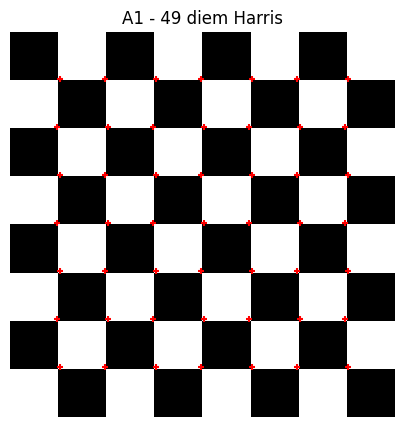

In [9]:

# A1 - ban co tong hop 8x8 o, moi o 16 px
cell_px = 16
so_o = 8

ban_co = np.zeros((cell_px * so_o, cell_px * so_o), dtype=np.float64)
for r in range(so_o):
    for c in range(so_o):
        if (r + c) % 2 == 1:
            ban_co[r * cell_px:(r + 1) * cell_px,
                   c * cell_px:(c + 1) * cell_px] = 255

# giao diem trong: bien giua pixel (k*16 - 1) va (k*16) -> toa do k*16 - 0.5
giao_diem = np.array([
    (r * cell_px - 0.5, c * cell_px - 0.5)
    for r in range(1, so_o)
    for c in range(1, so_o)
])


def danh_gia_ban_co(anh, ten):
    pts = harris_classic(anh, sigma_i=2.0, sigma_d=1.4, k=0.04, thresh_rel=0.01)

    d = np.linalg.norm(giao_diem[:, None, :] - pts[None, :, :2], axis=2)
    gan_nhat = d.min(axis=1)
    so_diem_gan = (d <= 1.0).sum(axis=1)

    print(f"\n{ten}")
    print("so diem phat hien:", len(pts))
    print("so giao diem trong:", len(giao_diem))
    print("giao diem tim thay (<= 1 px):", int((gan_nhat <= 1.0).sum()))
    print("giao diem co hon 1 diem trong 1 px:", int((so_diem_gan > 1).sum()))
    print("sai so dinh vi lon nhat (px):", round(float(gan_nhat.max()), 4))
    print("sai so dinh vi trung binh (px):", round(float(gan_nhat.mean()), 4))
    return pts


pts_255 = danh_gia_ban_co(ban_co, "ban co gia tri 0/255")
pts_01 = danh_gia_ban_co(ban_co / 255.0, "ban co gia tri 0/1")
pts_dao = danh_gia_ban_co(255 - ban_co, "ban co dao mau")

plt.figure(figsize=(5, 5))
plt.imshow(ban_co, cmap="gray")
plt.scatter(pts_255[:, 1], pts_255[:, 0], s=25, c="r", marker="+")
plt.title(f"A1 - {len(pts_255)} diem Harris")
plt.axis("off")
plt.show()

**Nhận xét kiểm chứng:**

- Kết quả thực tế: bàn cờ 8x8 ô, mỗi ô 16 px, có 49 giao điểm trong. Với cả ba cách dựng ảnh (giá trị 0/255, 0/1 và đảo màu), `harris_classic` đều trả đúng 49 điểm, tìm thấy 49/49 giao điểm và không có giao điểm nào bị tính hai lần. Sai số định vị lớn nhất là 0,7071 px.
- Đạt/chưa đạt và lý do: **Đạt** (yêu cầu ≤ 1 px). Giao điểm thật nằm ở tọa độ k·16 − 0,5, còn điểm trả về là tọa độ pixel nguyên, nên sai số 0,7071 px (√0,5²+0,5²) là mức nhỏ nhất có thể đạt. Trước khi sửa `nms_2d`, hai pixel chéo nhau ở giao điểm có R bằng nhau tuyệt đối nên đều được giữ: ảnh 0/1 cho 73 điểm, ảnh đảo màu cho 74 điểm. Bản sửa chỉ giữ một pixel khi đồng hạng nên kết quả không còn phụ thuộc cách dựng ảnh.

### Kiểm chứng A2 - Xoay ảnh 30 độ

Báo số điểm và repeatability bằng phép biến đổi tọa độ đúng. Người phụ trách: Gấm.

anh: home.jpg (384, 512)
goc xoay (do): 30.0
so diem anh goc: 332
so diem anh xoay: 290
so diem goc chieu vao trong anh xoay: 289
repeatability eps=1.0: 0.8235
repeatability eps=2.0: 0.8927
repeatability eps=3.0: 0.917
repeatability eps=3 (ma tran 3x3): 0.917
repeatability eps=3 (ham tung diem): 0.917


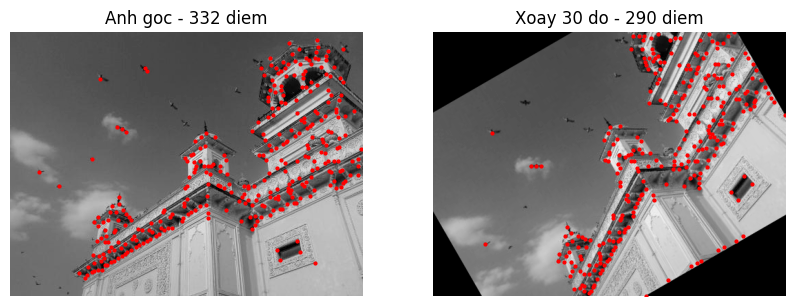

In [10]:

# A2 - xoay anh 30 do quanh tam anh
import cv2  # chi dung de doc anh va xoay anh, khong dung trong cai dat

anh_goc = cv2.imread(str(IMAGES_DIR / "home.jpg"), cv2.IMREAD_GRAYSCALE)
anh_goc = anh_goc.astype(np.float64)
h, w = anh_goc.shape

goc = 30.0
M = cv2.getRotationMatrix2D((w / 2, h / 2), goc, 1.0)
anh_xoay = cv2.warpAffine(anh_goc, M, (w, h))
H_xoay = np.vstack([M, [0, 0, 1]])

pts_goc = harris_classic(anh_goc)
pts_xoay = harris_classic(anh_xoay)


def xoay_diem(p):
    # p = (row, col) trong anh goc -> (row, col) trong anh xoay
    x, y = p[1], p[0]
    x2 = M[0, 0] * x + M[0, 1] * y + M[0, 2]
    y2 = M[1, 0] * x + M[1, 1] * y + M[1, 2]
    return (y2, x2)


rep_H = repeatability(pts_goc, pts_xoay, H_xoay, anh_xoay.shape, eps=3.0)
rep_ham = repeatability(pts_goc, pts_xoay, xoay_diem, anh_xoay.shape, eps=3.0)

# so diem cua A con nam trong anh B sau khi chieu
chieu = np.array([xoay_diem(p) for p in pts_goc[:, :2]])
trong_anh = ((chieu[:, 0] >= 0) & (chieu[:, 0] < h)
             & (chieu[:, 1] >= 0) & (chieu[:, 1] < w))

print("anh:", "home.jpg", anh_goc.shape)
print("goc xoay (do):", goc)
print("so diem anh goc:", len(pts_goc))
print("so diem anh xoay:", len(pts_xoay))
print("so diem goc chieu vao trong anh xoay:", int(trong_anh.sum()))
for e in (1.0, 2.0, 3.0):
    print(f"repeatability eps={e}:",
          round(repeatability(pts_goc, pts_xoay, H_xoay, anh_xoay.shape, eps=e), 4))
print("repeatability eps=3 (ma tran 3x3):", round(rep_H, 4))
print("repeatability eps=3 (ham tung diem):", round(rep_ham, 4))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(anh_goc, cmap="gray")
ax[0].scatter(pts_goc[:, 1], pts_goc[:, 0], s=4, c="r")
ax[0].set_title(f"Anh goc - {len(pts_goc)} diem")
ax[1].imshow(anh_xoay, cmap="gray")
ax[1].scatter(pts_xoay[:, 1], pts_xoay[:, 0], s=4, c="r")
ax[1].set_title(f"Xoay 30 do - {len(pts_xoay)} diem")
for a in ax:
    a.axis("off")
plt.show()

**Nhận xét kiểm chứng:**

- Kết quả thực tế: ảnh `home.jpg` (384x512) xoay 30° quanh tâm, giữ nguyên kích thước khung. Ảnh gốc có 332 điểm, ảnh xoay có 290 điểm, trong đó 289 điểm của ảnh gốc có ảnh chiếu nằm trong ảnh xoay. Repeatability là 0,8235 với eps = 1 px, 0,8927 với eps = 2 px và 0,9170 với eps = 3 px. Truyền ma trận 3x3 hay truyền hàm ánh xạ từng điểm đều cho cùng kết quả 0,9170.
- Đạt/chưa đạt và lý do: **Đạt**. Phép biến đổi tọa độ dùng đúng ma trận của `cv2.getRotationMatrix2D`. Repeatability chỉ tính các điểm có ảnh chiếu còn trong ảnh B. Khoảng 8% điểm không lặp lại là do nội suy khi xoay làm đổi cường độ quanh góc, và một số điểm gần mép bị phần nền đen sau khi xoay làm thay đổi đáp ứng. Harris dùng cửa sổ Gauss đẳng hướng nên gần như bất biến với phép xoay.

### Kiểm chứng A4 - Đối chiếu OpenCV

Dùng cv2.cornerHarris trong cell đối chiếu; báo điểm khớp trong 2-3 px. Người phụ trách: Gấm.

so diem cai dat nhom: 332
so diem OpenCV: 854
ti le diem nhom co diem OpenCV trong 2 px: 0.7349
ti le diem OpenCV co diem nhom trong 2 px: 0.3044
ti le diem nhom co diem OpenCV trong 3 px: 0.9006
ti le diem OpenCV co diem nhom trong 3 px: 0.4227
top 100: ti le diem nhom co diem OpenCV trong 3 px: 0.48


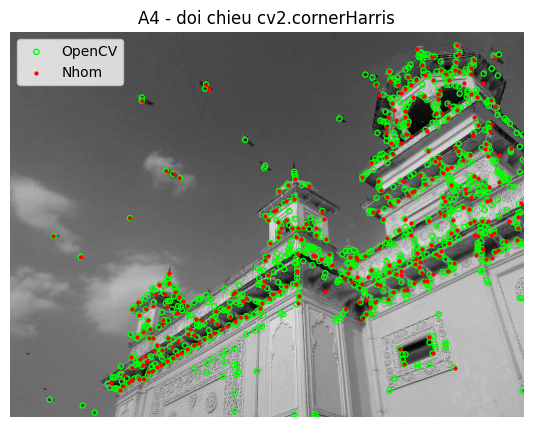

In [11]:

# A4 - doi chieu voi cv2.cornerHarris (chi dung trong cell doi chieu)
import cv2

anh = cv2.imread(str(IMAGES_DIR / "home.jpg"), cv2.IMREAD_GRAYSCALE)
anh = anh.astype(np.float64)

pts_ta = harris_classic(anh, sigma_i=2.0, sigma_d=1.4, k=0.04, thresh_rel=0.01)

# OpenCV: blockSize=5, ksize=3, k=0.04; NMS 3x3 va nguong 1% max nhu cai dat cua nhom
R_cv = cv2.cornerHarris(anh.astype(np.float32), 5, 3, 0.04).astype(np.float64)
mask_cv = nms_2d(R_cv, 3) & (R_cv > 0.01 * R_cv.max())
pts_cv = np.argwhere(mask_cv).astype(np.float64)

d = np.linalg.norm(pts_ta[:, None, :2] - pts_cv[None, :, :], axis=2)
gan_ta = d.min(axis=1)  # tu diem cua nhom den diem OpenCV gan nhat
gan_cv = d.min(axis=0)  # tu diem OpenCV den diem cua nhom gan nhat

print("so diem cai dat nhom:", len(pts_ta))
print("so diem OpenCV:", len(pts_cv))
for e in (2.0, 3.0):
    print(f"ti le diem nhom co diem OpenCV trong {e:.0f} px:",
          round(float((gan_ta <= e).mean()), 4))
    print(f"ti le diem OpenCV co diem nhom trong {e:.0f} px:",
          round(float((gan_cv <= e).mean()), 4))

# so sanh rieng 100 diem manh nhat cua moi ben
top_ta = pts_ta[:100, :2]
top_cv = pts_cv[np.argsort(-R_cv[mask_cv], kind="stable")[:100]]
d_top = np.linalg.norm(top_ta[:, None, :] - top_cv[None, :, :], axis=2)
print("top 100: ti le diem nhom co diem OpenCV trong 3 px:",
      round(float((d_top.min(axis=1) <= 3).mean()), 4))

plt.figure(figsize=(7, 5))
plt.imshow(anh, cmap="gray")
plt.scatter(pts_cv[:, 1], pts_cv[:, 0], s=14, facecolors="none", edgecolors="lime", label="OpenCV")
plt.scatter(pts_ta[:, 1], pts_ta[:, 0], s=4, c="r", label="Nhom")
plt.legend()
plt.axis("off")
plt.title("A4 - doi chieu cv2.cornerHarris")
plt.show()

**Nhận xét kiểm chứng:**

- Kết quả thực tế: trên ảnh `home.jpg`, cài đặt của nhóm (σI = 2, σD = 1,4, k = 0,04) cho 332 điểm. `cv2.cornerHarris` (blockSize = 5, ksize = 3, k = 0,04, cùng NMS 3x3 và ngưỡng 1% max) cho 854 điểm. 73,5% điểm của nhóm có điểm OpenCV trong 2 px, 90,1% trong 3 px. Theo chiều ngược lại, 42,3% điểm OpenCV có điểm của nhóm trong 3 px. Nếu chỉ lấy 100 điểm mạnh nhất mỗi bên thì 48% khớp trong 3 px.
- Đạt/chưa đạt và lý do: **Đạt về vị trí**. Gần như mọi điểm của nhóm đều trùng một điểm OpenCV trong 3 px. OpenCV cho nhiều điểm hơn và thứ hạng khác vì hai khác biệt về bộ lọc: (1) tích gradient được lấy tổng trên cửa sổ hộp 5x5 thay cho cửa sổ Gauss σI = 2, (2) đạo hàm dùng Sobel 3x3 trực tiếp trên ảnh, không làm mờ Gauss trước theo σD = 1,4. Cả hai đều làm mờ ít hơn, nên đáp ứng của OpenCV nhạy hơn với chi tiết nhỏ và có nhiều cực đại địa phương vượt ngưỡng 1% hơn. Hệ số σD² không góp phần vào khác biệt này: với σD cố định, nó chỉ nhân cả R với hằng số σD⁴ > 0, nên vị trí cực đại và ngưỡng tương đối 1% × max(R) giữ nguyên.

## Thí nghiệm - Rà số đo và điều kiện so sánh của ba cặp

Tự chọn dữ liệu, trục quét, số đo và kết luận. Theo mục 5.1, mỗi cặp cần bằng chứng khác biệt, quét tham số có ý nghĩa và giải thích cơ chế. Nếu thực tế dùng AI hỗ trợ cell thí nghiệm, ghi prompt nguyên văn ngay phía trên cell đó.

### Thiết kế và bằng chứng khác biệt

Nêu ảnh nào, vì sao chọn, giữ cố định điều kiện gì và đo đại lượng nào. Trình bày kết quả của hai phương pháp.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét từ số liệu đã chạy:**



### Quét tham số

Ghi trục quét, giá trị thử và các điều kiện giữ cố định; trình bày đường cong hoặc điểm chuyển hành vi.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét từ số liệu đã chạy:**



### Giải thích kết quả

Điền kết quả đo, giải thích đại lượng nào thay đổi, ở bước nào và vì sao. Báo cả trường hợp chưa cải thiện.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: 
- Mục đích: 
- Prompt nguyên văn: 
- Phần đã tự sửa và kiểm tra: 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

**Nhận xét từ số liệu đã chạy:**



## Bàn giao cho nhóm trưởng

- [ ] Đúng giao diện hàm và quy ước tọa độ.
- [ ] Restart & Run All chạy được, đã lưu output.
- [ ] Ảnh cần dùng có trong images/ tại gốc repo; dùng IMAGES_DIR để đọc ảnh.
- [ ] Kiểm chứng và thí nghiệm có số đo thực tế.
- [ ] Cell thí nghiệm có dùng AI ghi đúng prompt ngay phía trên.
- [ ] Đã mở Pull Request và ghi nguồn các hàm dùng chung.